# LSTM and GRU with regularization

**Owner:** Yogesh Modi. Phase 2, deep learning (notebook 03 of 07).

## Purpose

Train recurrent models (LSTM and GRU) that read the last 30 cycles of the 14 useful sensors and predict Remaining Useful Life (RUL). Measure, one factor at a time, what each regularizer and each capacity choice does, and compare the result with the Phase 1 models. Phase 1 weaknesses to address: underprediction of engines with true RUL above 200, a rolling window that only sees recent behaviour, and an RMSE much larger than MAE.

## Method

**Data and protocol.** Windows come from `src/sequences.py` (window 30, scaler fitted on the 80 training engines only, no look-ahead). Training uses all windows of the 80 training engines. The 20 validation engines supply (a) all their windows, used for early stopping and for choosing a configuration, and (b) the 100 fixed validation points, used only to report. The test set is never scored here: the notebook only writes test predictions to a file. Targets are the true, uncapped RUL divided by 100.

**Training.** AdamW (learning rate 1e-3), MSE loss, batch size 256, gradient clipping at 1.0, at most 60 epochs, early stopping on validation-window MAE with the best weights restored. All runs use CPU: this model size is as fast on CPU as on the GPU and CPU runs are deterministic, so every number in this notebook can be reproduced. Independent runs are spread over 6 worker processes (one thread each).

**Experiment design.** Starting from a baseline (2 layers, 64 hidden units, dropout 0.2, weight decay 1e-4, patience 8, seed 42) each factor is changed alone, for both GRU and LSTM:

| Factor | Values |
| --- | --- |
| Dropout | 0, 0.1, **0.2**, 0.3, 0.5 |
| Weight decay | 0, 1e-5, **1e-4**, 1e-3 |
| Early-stopping patience | 3, **8**, 15, and no early stopping (60 epochs, last epoch kept) |
| Hidden size | 32, **64**, 128 |
| Layers | 1, **2**, 3 |

The baseline values are in bold. A further run without gradient clipping is a diagnostic for the gradient-norm figure.

**Selection rule (written before any result is looked at).**

1. The score used to choose a configuration is the MAE in cycles over *all windows of the 20 validation engines*, taken at the epoch whose weights are kept. It is not the 100-point score, because 100 points are too few and too noisy to choose from.
2. For each factor, the winner is the value with the lowest score. A difference below 0.05 cycles counts as a tie, and a tie goes to the model with fewer parameters.
3. One extra candidate combines the five per-factor winners.
4. The candidate pool is the baseline, every one-factor run (including no early stopping) and the combined run. The no-clipping run is a diagnostic and is not a candidate. The final configuration of each model (LSTM and GRU separately) is the pool member with the lowest score, with the same tie rule.
5. The chosen configuration is then trained with seeds 42, 43 and 44. The seed 42 run is saved as `lstm_v1` and `gru_v1`. Only now are the 100-point numbers reported for the chosen configuration (the baseline's 100-point numbers are also shown, as Task B asks).

**Caveat.** Early stopping and configuration choice both use the 20 validation engines, so validation scores are slightly optimistic. Choosing the minimum over about 16 single-seed runs per model adds a small winner's-curse bias on top. The held-out test set, scored once in notebook 07, is the unbiased check.

## Results

### Setup

Imports, paths and plotting defaults. `ROOT` is found from the working directory, so the notebook must run from `notebooks/phase2/`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # run from notebooks/phase2
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import rnn_experiments as rx
import train
from dl_models import build_model
from evaluation import split_train_val, validation_points
from load_data import load_train
from sequences import DEFAULT_WINDOW

RESULTS = ROOT / "results" / "phase2"
FIG_DIR = RESULTS / "figures"
MODEL_DIR = RESULTS / "models"
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

WORKERS = 6
SEEDS = (42, 43, 44)
TIE = 0.05  # cycles; differences below this are ties (smaller model wins)
KINDS = ("gru", "lstm")
COLORS = {"gru": "#1f77b4", "lstm": "#d62728"}
plt.rcParams.update({"savefig.dpi": 150, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(1)


def save_fig(fig, name):
    """Save a figure under results/phase2/figures and show it."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()

### Data

Build the windows once (this reuses Prateek's pipeline through `rnn_experiments.get_data`) and print the shapes. The scaler is fitted on the 80 training engines only.

In [2]:
data = rx.get_data(DEFAULT_WINDOW)
train_df, val_df = split_train_val(load_train())
points = validation_points(val_df)
print("training engines:", train_df["engine_id"].nunique(), "| windows:", data["X_tr"].shape)
print("validation engines:", val_df["engine_id"].nunique(), "| windows:", data["X_va"].shape)
print("100 validation points:", data["X_pt"].shape, "| test points:", data["X_te"].shape)
assert (data["keys_pt"][["engine_id", "cycle"]].to_numpy() == points[["engine_id", "cycle"]].to_numpy()).all()

training engines: 80 | windows: (16390, 30, 14)
validation engines: 20 | windows: (4241, 30, 14)
100 validation points: (100, 30, 14) | test points: (100, 30, 14)


### Why the effective sample size is closer to 80 than to 16,000

There are 16,390 training windows but only 80 engines. Two consecutive windows of one engine share 29 of their 30 cycles (97% overlap), and every window of an engine ends at a point on the same degradation path with the same hidden wear trajectory. The windows of one engine are therefore far from independent: what the model really learns from is 80 degradation histories. This has two consequences. First, a model can memorise the specific histories of the training engines (overfit) while its training loss keeps falling, so regularization matters. Second, validation must be split by engine: if windows were split at random, a validation window would have a near-copy in the training set and the validation error would be much too optimistic.

In [3]:
per_engine = train_df.groupby("engine_id").size()
print(f"windows per training engine: mean {per_engine.mean():.0f}, min {per_engine.min()}, max {per_engine.max()}")
print(f"overlap of consecutive windows: {(DEFAULT_WINDOW - 1) / DEFAULT_WINDOW:.1%}")

windows per training engine: mean 205, min 128, max 341
overlap of consecutive windows: 96.7%


### Task B: baseline GRU and LSTM

Train the default GRU and LSTM (2 layers, 64 hidden, dropout 0.2, seed 42). `final=True` also scores the 100 fixed validation points and predicts the test points (no test metric is computed).

In [4]:
base_runs = rx.run_many([{"kind": k, "final": True} for k in KINDS], workers=2)
BASE = dict(zip(KINDS, base_runs))
for k in KINDS:
    r = BASE[k]
    print(f"{k}: params {r['n_params']}, epochs run {r['epochs_run']}, best epoch {r['best_epoch']}, val-window MAE {r['val_window_mae']:.2f}")

gru: params 40385, epochs run 20, best epoch 12, val-window MAE 26.87
lstm: params 53825, epochs run 18, best epoch 10, val-window MAE 28.42


Learning curves of the two baselines: training loss (MSE of RUL/100, dropout active) and validation-window MAE per epoch. The dotted line marks the epoch whose weights were kept.

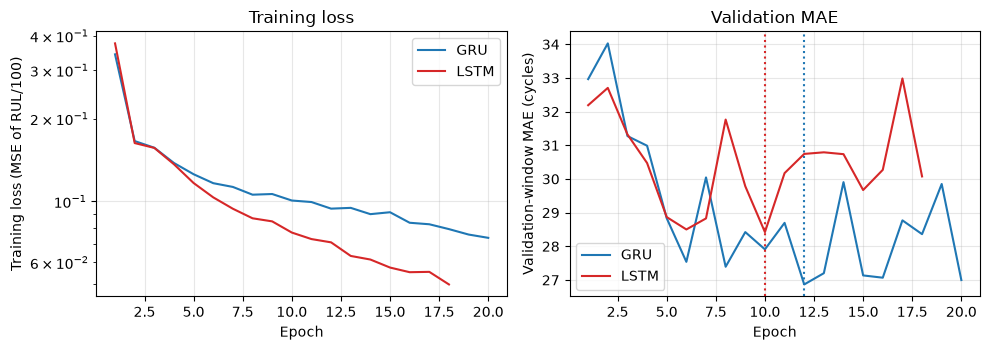

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for k in KINDS:
    h = BASE[k]["history"]
    epochs = np.arange(1, len(h["val_mae"]) + 1)
    axes[0].plot(epochs, h["train_loss"], color=COLORS[k], label=k.upper())
    axes[1].plot(epochs, h["val_mae"], color=COLORS[k], label=k.upper())
    axes[1].axvline(h["best_epoch"][0], color=COLORS[k], ls=":")
axes[0].set(xlabel="Epoch", ylabel="Training loss (MSE of RUL/100)", yscale="log", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation-window MAE (cycles)", title="Validation MAE")
for ax in axes:
    ax.legend()
save_fig(fig, "rnn_learning_curves.png")

*Figure: baseline learning curves. Validation MAE flattens or rises after a few epochs while training loss keeps falling, which is why early stopping is used.*

Baseline scores on the 100 fixed validation points next to the Phase 1 results, read from `results/phase1/final_results.csv`.

In [6]:
phase1 = pd.read_csv(ROOT / "results" / "phase1" / "final_results.csv")
phase1 = phase1[phase1["set"] == "validation"][["model", "mae", "rmse", "early_mae", "late_mae"]]
ours = pd.DataFrame(
    [{"model": f"{k}_baseline", **BASE[k]["points"]} for k in KINDS]
)
print(pd.concat([phase1, ours], ignore_index=True).round(2).to_string(index=False))

            model   mae  rmse  early_mae  late_mae
           ols_v1 32.86 42.92      47.31     28.79
   elastic_net_v2 31.66 41.77      46.31     27.52
    random_forest 25.03 40.17      49.33     18.17
gradient_boosting 26.12 40.17      50.92     19.13
     gru_baseline 22.83 36.35      46.22     16.23
    lstm_baseline 21.83 34.01      40.06     16.68


### Task C: regularization and capacity sweeps

Run every one-factor change for both models in parallel. Each run returns the validation-window MAE at the kept epoch (the selection score), the final training loss, and the training MAE in evaluation mode (no dropout), so the train-versus-validation gap can be plotted. The 100-point numbers are not computed for these runs.

In [7]:
GRID = {
    "dropout": [0, 0.1, 0.2, 0.3, 0.5],
    "weight_decay": [0, 1e-5, 1e-4, 1e-3],
    "patience": [3, 8, 15],
    "hidden": [32, 64, 128],
    "layers": [1, 2, 3],
}
NO_ES = {"patience": 60, "restore_best": False}  # never stops; keeps the last epoch
LABEL_NO_ES = "none (60 ep)"

jobs, meta = [], []
for k in KINDS:
    for factor, values in GRID.items():
        for v in values:
            if v == rx.DEFAULTS[factor]:
                continue  # the baseline run already covers the default value
            jobs.append({"kind": k, factor: v})
            meta.append((k, factor, v))
    jobs.append({"kind": k, **NO_ES})
    meta.append((k, "patience", LABEL_NO_ES))
    jobs.append({"kind": k, "grad_clip": None})
    meta.append((k, "grad_clip", "off"))
print("sweep runs:", len(jobs), "(plus the 2 baselines already trained)")
sweep_results = rx.run_many(jobs, workers=WORKERS)

sweep runs: 30 (plus the 2 baselines already trained)


Collect every run (the baseline appears under each factor at its default value) into one table and save it as `rnn_regularization.csv`.

In [8]:
runs = []  # one record per run: kind, factor, value, result
for (k, factor, v), res in zip(meta, sweep_results):
    runs.append({"kind": k, "factor": factor, "value": v, "res": res})
for k in KINDS:
    for factor in GRID:
        runs.append({"kind": k, "factor": factor, "value": rx.DEFAULTS[factor], "res": BASE[k]})

reg_df = pd.DataFrame(
    [
        {
            "model": r["kind"], "factor": r["factor"], "value": r["value"],
            "val_window_mae": r["res"]["val_window_mae"],
            "train_loss_final": r["res"]["train_loss_final"],
            "train_mae": r["res"]["train_mae"],
            "best_epoch": r["res"]["best_epoch"], "epochs_run": r["res"]["epochs_run"],
            "n_params": r["res"]["n_params"],
        }
        for r in runs
    ]
)
reg_df.to_csv(RESULTS / "rnn_regularization.csv", index=False)
print(reg_df.round(3).to_string(index=False))

model       factor        value  val_window_mae  train_loss_final  train_mae  best_epoch  epochs_run  n_params
  gru      dropout            0          26.950             0.083     19.515          12          20     40385
  gru      dropout          0.1          26.965             0.099     21.397           8          16     40385
  gru      dropout          0.3          26.785             0.099     20.206          13          21     40385
  gru      dropout          0.5          27.164             0.101     20.055          16          24     40385
  gru weight_decay            0          26.856             0.082     18.203          16          24     40385
  gru weight_decay      0.00001          26.856             0.082     18.203          16          24     40385
  gru weight_decay        0.001          26.800             0.090     19.733          13          21     40385
  gru     patience            3          27.393             0.106     20.285           8          11     40385
 

Validation-window MAE (solid) and training MAE in evaluation mode (dashed) against each setting. The distance between the two lines is the generalization gap.

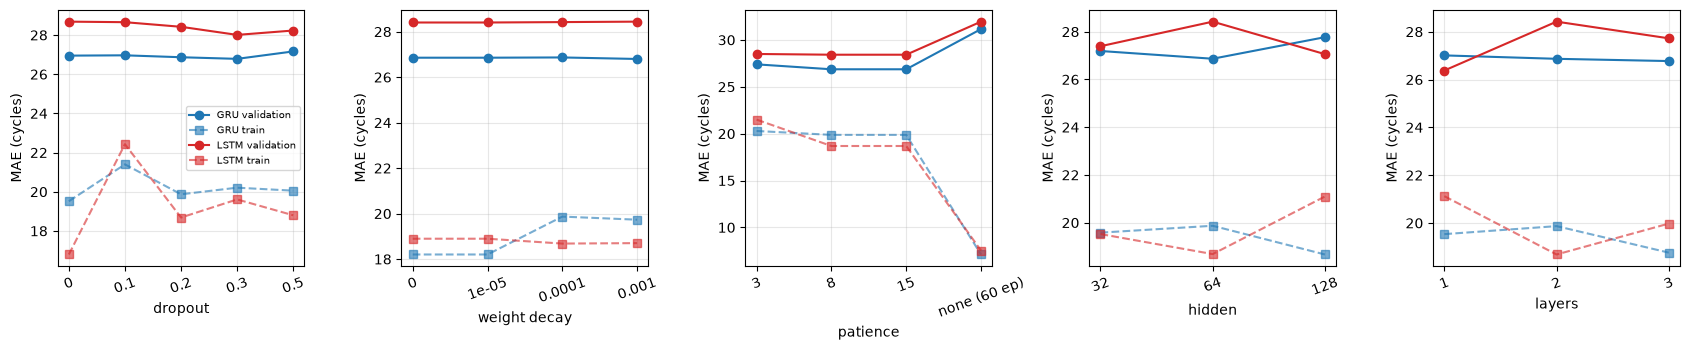

In [9]:
FACTORS = ["dropout", "weight_decay", "patience", "hidden", "layers"]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, factor in zip(axes, FACTORS):
    order = GRID[factor] + ([LABEL_NO_ES] if factor == "patience" else [])
    for k in KINDS:
        sub = {r["value"]: r["res"] for r in runs if r["kind"] == k and r["factor"] == factor}
        xs = range(len(order))
        ax.plot(xs, [sub[v]["val_window_mae"] for v in order], "o-", color=COLORS[k], label=f"{k.upper()} validation")
        ax.plot(xs, [sub[v]["train_mae"] for v in order], "s--", color=COLORS[k], alpha=0.6, label=f"{k.upper()} train")
    ax.set_xticks(list(range(len(order))))
    ax.set_xticklabels([str(v) for v in order], rotation=20)
    ax.set(xlabel=factor.replace("_", " "), ylabel="MAE (cycles)")
axes[0].legend(fontsize=7)
save_fig(fig, "rnn_regularization_sweeps.png")

*Figure: one-factor sweeps. Each point is one run with seed 42, so differences of about 1 cycle are within seed noise (see the seed study below).*

### Gradient clipping

Without clipping, a recurrent network multiplies the gradient by the recurrent Jacobian once per time step, so over 30 steps the gradient norm can grow or shrink geometrically. Clipping rescales the gradient whenever its norm exceeds 1.0. The figure shows the mean gradient norm per epoch (measured before clipping) and the validation MAE with and without clipping.

gru: max mean grad norm  clip 1.57 | no clip 1.13; best val MAE clip 26.87 | no clip 27.09
lstm: max mean grad norm  clip 1.31 | no clip 0.99; best val MAE clip 28.42 | no clip 27.86


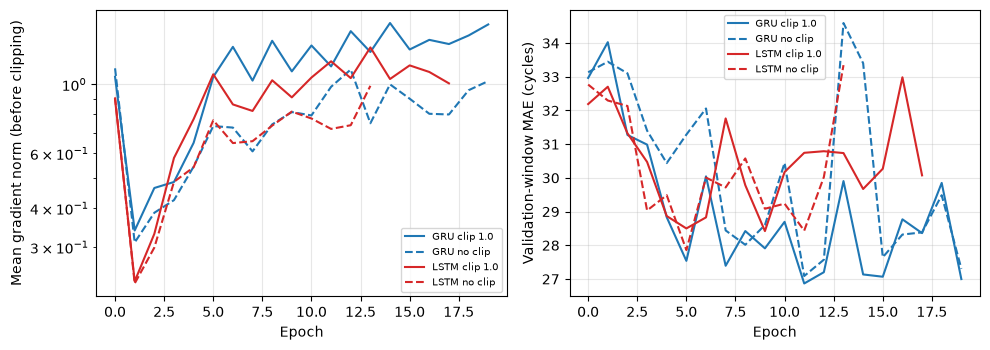

In [10]:
clip_off = {r["kind"]: r["res"] for r in runs if r["factor"] == "grad_clip"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for k in KINDS:
    on, off = BASE[k]["history"], clip_off[k]["history"]
    axes[0].plot(on["grad_norm"], color=COLORS[k], label=f"{k.upper()} clip 1.0")
    axes[0].plot(off["grad_norm"], color=COLORS[k], ls="--", label=f"{k.upper()} no clip")
    axes[1].plot(on["val_mae"], color=COLORS[k], label=f"{k.upper()} clip 1.0")
    axes[1].plot(off["val_mae"], color=COLORS[k], ls="--", label=f"{k.upper()} no clip")
    print(f"{k}: max mean grad norm  clip {max(on['grad_norm']):.2f} | no clip {max(off['grad_norm']):.2f};"
          f" best val MAE clip {min(on['val_mae']):.2f} | no clip {min(off['val_mae']):.2f}")
axes[0].set(xlabel="Epoch", ylabel="Mean gradient norm (before clipping)", yscale="log")
axes[1].set(xlabel="Epoch", ylabel="Validation-window MAE (cycles)")
for ax in axes:
    ax.legend(fontsize=7)
save_fig(fig, "rnn_gradient_norm.png")

*Figure: gradient norm per epoch and validation MAE with and without clipping (one run each, seed 42).*

### Choosing the final configuration

Apply the selection rule written in the Method section. First the per-factor winners, then the combined candidate, then the overall winner for each model.

In [11]:
def choose(cands):
    """Lowest validation-window MAE; differences below TIE go to the fewer-parameter model."""
    best = min(c["val_window_mae"] for c in cands)
    tied = [c for c in cands if c["val_window_mae"] <= best + TIE]
    return min(tied, key=lambda c: c["n_params"])

FACTOR_KEYS = {
    "dropout": ["dropout"], "weight_decay": ["weight_decay"],
    "patience": ["patience", "restore_best"], "hidden": ["hidden"], "layers": ["layers"],
}
combo_jobs, winners = [], {}
for k in KINDS:
    combo = {"kind": k}
    for factor, keys in FACTOR_KEYS.items():
        win = choose([r["res"] for r in runs if r["kind"] == k and r["factor"] == factor])
        combo.update({key: win["cfg"][key] for key in keys})
        winners[(k, factor)] = {key: win["cfg"][key] for key in keys}
    combo_jobs.append(combo)
    print(k, "per-factor winners:", {f: winners[(k, f)] for f in FACTOR_KEYS})
combo_results = dict(zip(KINDS, rx.run_many(combo_jobs, workers=2)))

gru per-factor winners: {'dropout': {'dropout': 0.3}, 'weight_decay': {'weight_decay': 0.001}, 'patience': {'patience': 15, 'restore_best': True}, 'hidden': {'hidden': 64}, 'layers': {'layers': 3}}
lstm per-factor winners: {'dropout': {'dropout': 0.3}, 'weight_decay': {'weight_decay': 0}, 'patience': {'patience': 15, 'restore_best': True}, 'hidden': {'hidden': 128}, 'layers': {'layers': 1}}


In [12]:
CHOSEN = {}
for k in KINDS:
    pool = [r["res"] for r in runs if r["kind"] == k and r["factor"] != "grad_clip"] + [combo_results[k]]
    CHOSEN[k] = choose(pool)
    cfg = CHOSEN[k]["cfg"]
    print(f"{k}: combined candidate val MAE {combo_results[k]['val_window_mae']:.2f}; "
          f"chosen val-window MAE {CHOSEN[k]['val_window_mae']:.2f} with "
          f"hidden={cfg['hidden']}, layers={cfg['layers']}, dropout={cfg['dropout']}, "
          f"weight_decay={cfg['weight_decay']}, patience={cfg['patience']}, restore_best={cfg['restore_best']}")

gru: combined candidate val MAE 27.15; chosen val-window MAE 26.78 with hidden=64, layers=2, dropout=0.3, weight_decay=0.0001, patience=8, restore_best=True
lstm: combined candidate val MAE 26.81; chosen val-window MAE 26.38 with hidden=64, layers=1, dropout=0.2, weight_decay=0.0001, patience=8, restore_best=True


### Seeds

Retrain each chosen configuration with seeds 42, 43 and 44. This is the first time the 100 fixed validation points are scored for the chosen models. The seed 42 run is the saved model.

In [13]:
seed_jobs = [{**CHOSEN[k]["cfg"], "seed": s, "final": True} for k in KINDS for s in SEEDS]
seed_runs = rx.run_many(seed_jobs, workers=WORKERS)
FINAL = {(job["kind"], job["seed"]): res for job, res in zip(seed_jobs, seed_runs)}
rows = []
for k in KINDS:
    for s in SEEDS:
        r = FINAL[(k, s)]
        rows.append({"model": k, "seed": s, **r["points"], "val_window_mae": r["val_window_mae"], "epochs_run": r["epochs_run"]})
seed_df = pd.DataFrame(rows)
print(seed_df.round(2).to_string(index=False))

model  seed   mae  rmse  early_mae  late_mae  val_window_mae  epochs_run
  gru    42 23.18 36.34      43.34     17.49           26.78          21
  gru    43 22.42 35.86      45.44     15.93           27.01          24
  gru    44 23.34 37.61      47.36     16.57           27.20          19
 lstm    42 19.41 34.45      43.73     12.55           26.38          15
 lstm    43 19.19 30.34      38.66     13.70           27.17          14
 lstm    44 21.83 34.74      44.56     15.42           27.22          19


### Outputs

Write the summary table (seed 42 scores for the saved model, standard deviation over the three seeds), the prediction files, the configuration files and the model weights. Predictions are in cycles and clipped at 0. Validation rows follow `validation_points` order and test rows follow `test_points` order (engines 1 to 100).

In [14]:
NAMES = {"lstm": "lstm_v1", "gru": "gru_v1"}
summary = []
for k in ("lstm", "gru"):
    pts = [FINAL[(k, s)]["points"] for s in SEEDS]
    summary.append({
        "model": NAMES[k], **FINAL[(k, 42)]["points"],
        "mae_std": np.std([p["mae"] for p in pts], ddof=1),
        "rmse_std": np.std([p["rmse"] for p in pts], ddof=1),
        "mae_mean_3seeds": np.mean([p["mae"] for p in pts]),
        "rmse_mean_3seeds": np.mean([p["rmse"] for p in pts]),
    })
summary_df = pd.DataFrame(summary)
summary_df.to_csv(RESULTS / "summary_rnn.csv", index=False)
print(summary_df.round(2).to_string(index=False))

val_out = data["keys_pt"][["engine_id", "cycle"]].copy()
test_out = data["keys_te"][["engine_id"]].copy()
for k in ("lstm", "gru"):
    val_out[NAMES[k]] = FINAL[(k, 42)]["val_pred"]
    test_out[NAMES[k]] = FINAL[(k, 42)]["test_pred"]
val_out.to_csv(RESULTS / "val_predictions_rnn.csv", index=False)
test_out.to_csv(RESULTS / "test_predictions_rnn.csv", index=False)

for k in ("lstm", "gru"):
    res = FINAL[(k, 42)]
    cfg = res["cfg"]
    config = {
        "model": NAMES[k], "kind": k,
        "hidden": cfg["hidden"], "layers": cfg["layers"], "dropout": cfg["dropout"],
        "window": cfg["window"], "seed": cfg["seed"],
        "optimizer": "AdamW", "lr": cfg["lr"], "weight_decay": cfg["weight_decay"],
        "batch_size": 256, "grad_clip": cfg["grad_clip"], "loss": "MSE on RUL/100",
        "max_epochs": cfg["epochs"], "patience": cfg["patience"], "restore_best": cfg["restore_best"],
        "epochs_run": res["epochs_run"], "best_epoch": res["best_epoch"],
        "best_val_window_mae": res["val_window_mae"], "n_params": res["n_params"],
        "val_points": res["points"],
        "seeds_reported": list(SEEDS),
    }
    (RESULTS / f"config_{k}.json").write_text(json.dumps(config, indent=2))
    model = build_model(k, **rx.model_kwargs(cfg))
    model.load_state_dict(res["state_dict"])
    train.save_model(model, MODEL_DIR / f"{NAMES[k]}.pt")

  model   mae  rmse  early_mae  late_mae  mae_std  rmse_std  mae_mean_3seeds  rmse_mean_3seeds
lstm_v1 19.41 34.45      43.73     12.55     1.46      2.46            20.14             33.18
 gru_v1 23.18 36.34      43.34     17.49     0.49      0.90            22.98             36.61


Check the files: schema, row counts, order, no NaN, and that a reloaded model reproduces the saved predictions (this is how Kapish will load them).

In [15]:
for name, df, cols in [
    ("val_predictions_rnn.csv", val_out, ["engine_id", "cycle", "lstm_v1", "gru_v1"]),
    ("test_predictions_rnn.csv", test_out, ["engine_id", "lstm_v1", "gru_v1"]),
]:
    saved = pd.read_csv(RESULTS / name)
    assert list(saved.columns) == cols and len(saved) == 100 and not saved.isna().any().any(), name
assert (pd.read_csv(RESULTS / "val_predictions_rnn.csv")[["engine_id", "cycle"]].to_numpy()
        == points[["engine_id", "cycle"]].to_numpy()).all()
assert list(pd.read_csv(RESULTS / "test_predictions_rnn.csv")["engine_id"]) == list(range(1, 101))
for k in ("lstm", "gru"):
    cfg = json.loads((RESULTS / f"config_{k}.json").read_text())
    reloaded = train.load_model(k, MODEL_DIR / f"{NAMES[k]}.pt", hidden=cfg["hidden"], layers=cfg["layers"], dropout=cfg["dropout"])
    assert np.allclose(train.predict(reloaded, data["X_pt"]), val_out[NAMES[k]].to_numpy(), atol=1e-3), k
print("all output files pass the schema and reload checks")

all output files pass the schema and reload checks


### Analysis

**Predicted versus true RUL** for the 100 validation points (seed 42 models), and **error by true-RUL band** with the number of points per band. The band error is the mean of (prediction minus truth); negative means underprediction.

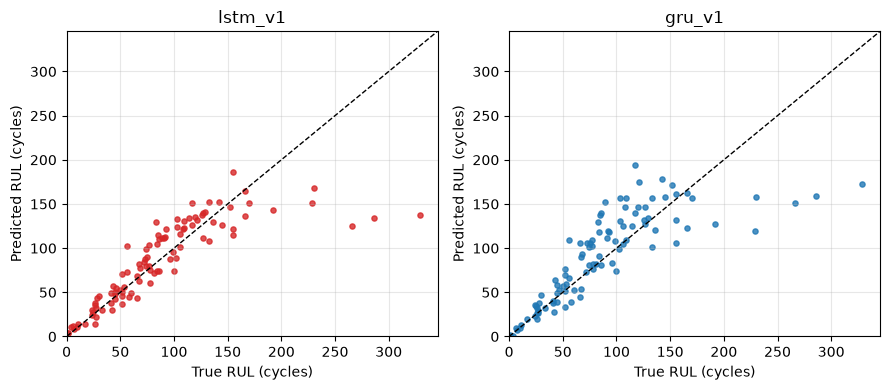

In [16]:
y_true = data["y_pt"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, k in zip(axes, ("lstm", "gru")):
    pred = val_out[NAMES[k]].to_numpy()
    ax.scatter(y_true, pred, s=14, color=COLORS[k], alpha=0.8)
    lim = max(y_true.max(), pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set(xlabel="True RUL (cycles)", ylabel="Predicted RUL (cycles)", title=NAMES[k], xlim=(0, lim), ylim=(0, lim))
save_fig(fig, "rnn_pred_vs_true.png")

*Figure: predicted against true RUL on the 100 validation points. The dashed line is a perfect prediction.*

  model    band  n  mean_error        mae
lstm_v1    0-50 27    3.400000   6.300000
lstm_v1  50-100 37    8.000000  15.300000
lstm_v1 100-150 23    6.700000  16.200001
lstm_v1 150-200  8  -18.299999  26.000000
lstm_v1    200+  5 -124.699997 124.699997
 gru_v1    0-50 27    2.700000   5.400000
 gru_v1  50-100 37   16.400000  21.900000
 gru_v1 100-150 23   17.600000  24.400000
 gru_v1 150-200  8  -21.200001  27.900000
 gru_v1    200+  5 -115.800003 115.800003


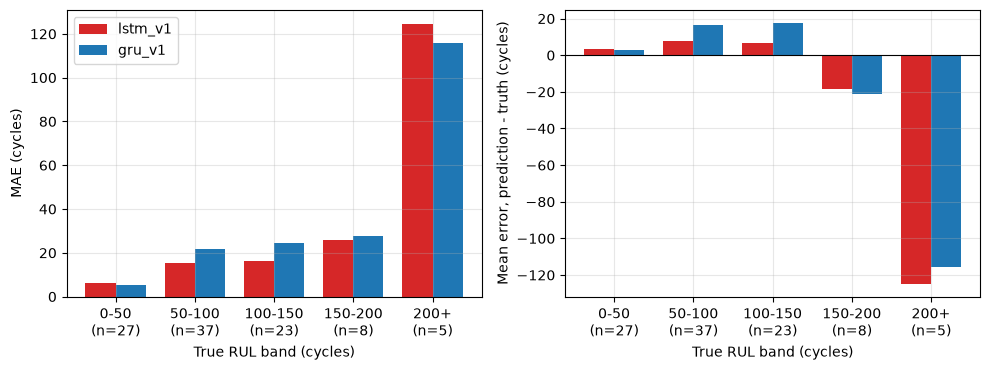

In [17]:
edges = [0, 50, 100, 150, 200, np.inf]
labels = ["0-50", "50-100", "100-150", "150-200", "200+"]
band = pd.cut(y_true, bins=edges, labels=labels, right=False)
band_rows = []
for k in ("lstm", "gru"):
    err = val_out[NAMES[k]].to_numpy() - y_true
    for b in labels:
        m = np.asarray(band == b)
        band_rows.append({"model": NAMES[k], "band": b, "n": int(m.sum()),
                          "mean_error": err[m].mean() if m.any() else np.nan,
                          "mae": np.abs(err[m]).mean() if m.any() else np.nan})
band_df = pd.DataFrame(band_rows)
print(band_df.round(1).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
width = 0.38
for i, k in enumerate(("lstm", "gru")):
    sub = band_df[band_df["model"] == NAMES[k]]
    xs = np.arange(len(labels)) + (i - 0.5) * width
    axes[0].bar(xs, sub["mae"], width, color=COLORS[k], label=NAMES[k])
    axes[1].bar(xs, sub["mean_error"], width, color=COLORS[k], label=NAMES[k])
counts = band_df[band_df["model"] == "lstm_v1"]["n"].tolist()
for ax, ylabel in zip(axes, ["MAE (cycles)", "Mean error, prediction - truth (cycles)"]):
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(labels, counts)])
    ax.set(xlabel="True RUL band (cycles)", ylabel=ylabel)
axes[1].axhline(0, color="k", lw=0.8)
axes[0].legend()
save_fig(fig, "rnn_error_by_band.png")

*Figure: error by true-RUL band, with the number of validation points in each band.*

**Comparison with Random Forest** (Phase 1, MAE 25.03 read from the file) using the three-seed mean and standard deviation, and **cost** of the two architectures: parameters and training time per epoch, measured in serial runs (5 epochs, one thread, nothing else running), for the chosen configurations and for a matched 2-layer, 64-unit pair (the chosen LSTM has one layer, so only the matched pair compares the cell types fairly).

In [18]:
rf = phase1[phase1["model"] == "random_forest"].iloc[0]
for k in ("lstm", "gru"):
    maes = [FINAL[(k, s)]["points"]["mae"] for s in SEEDS]
    rmses = [FINAL[(k, s)]["points"]["rmse"] for s in SEEDS]
    gap = rf["mae"] - np.mean(maes)
    print(f"{NAMES[k]}: MAE {np.mean(maes):.2f} +/- {np.std(maes, ddof=1):.2f}, RMSE {np.mean(rmses):.2f} +/- {np.std(rmses, ddof=1):.2f}; "
          f"Random Forest MAE {rf['mae']:.2f} (RMSE {rf['rmse']:.2f}); MAE gap {gap:+.2f} cycles")

timing = []
for setting, extra in [("chosen configuration", None), ("matched 2 layers x 64 units", {})]:
    for k in ("lstm", "gru"):
        cfg = CHOSEN[k]["cfg"] if extra is None else {"kind": k}
        t = rx.run_one({**cfg, "epochs": 5, "patience": 99, "restore_best": True})
        timing.append({"setting": setting, "model": k, "params": t["n_params"], "sec_per_epoch": round(t["sec_per_epoch"], 2)})
print(pd.DataFrame(timing).to_string(index=False))

lstm_v1: MAE 20.14 +/- 1.46, RMSE 33.18 +/- 2.46; Random Forest MAE 25.03 (RMSE 40.17); MAE gap +4.89 cycles
gru_v1: MAE 22.98 +/- 0.49, RMSE 36.61 +/- 0.90; Random Forest MAE 25.03 (RMSE 40.17); MAE gap +2.05 cycles


                    setting model  params  sec_per_epoch
       chosen configuration  lstm   20545           0.85
       chosen configuration   gru   40385           1.16
matched 2 layers x 64 units  lstm   53825           1.48
matched 2 layers x 64 units   gru   40385           1.14


**Which factor mattered most.** For each factor, the spread (largest minus smallest) of the validation-window MAE across its values, for each model.

In [19]:
spread = (
    reg_df.groupby(["model", "factor"])["val_window_mae"].agg(lambda s: s.max() - s.min())
    .unstack("model").loc[FACTORS + ["grad_clip"]].round(2)
)
spread.columns = [c.upper() + " spread (cycles)" for c in spread.columns]
print(spread.to_string())

              GRU spread (cycles)  LSTM spread (cycles)
factor                                                 
dropout                      0.38                  0.68
weight_decay                 0.07                  0.04
patience                     4.29                  3.53
hidden                       0.90                  1.36
layers                       0.24                  2.04
grad_clip                    0.00                  0.00


## Conclusion

All numbers below are printed above or in `results/phase2/`; scores are on the 100 fixed validation points unless stated, and the saved models are the seed 42 runs.

**Versus Random Forest.** The chosen LSTM (1 layer, 64 units, dropout 0.2) reached a three-seed MAE of 20.14 +/- 1.46 cycles and RMSE 33.18 +/- 2.46, against 25.03 and 40.17 for Random Forest. The chosen GRU (2 layers, 64 units, dropout 0.3) reached 22.98 +/- 0.49 and 36.61 +/- 0.90. Both MAE gaps (4.89 and 2.05 cycles) are larger than the seed standard deviation, and the RMSE falls more than the MAE, so the large errors shrink as well. Two cautions: the standard deviation comes from only three seeds and measures training noise, not the sampling noise of 100 points from 20 engines; and the validation scores are slightly optimistic because early stopping and configuration choice used the same 20 engines. The test set will tell.

**Where the gain comes from.** The late-life MAE (true RUL <= 125) of the seed 42 models is 12.55 (LSTM) and 17.49 (GRU), against 18.17 for Random Forest. The early-life MAE (true RUL > 125) is 43.73 and 43.34, against 49.33: still large, so early life remains the hard part.

**Underprediction above 200 cycles is not fixed.** In the 200+ band (5 validation points) the mean error is -124.7 cycles for the LSTM and -115.8 for the GRU, essentially the -120 seen with the Phase 1 linear models. Five points are too few to conclude much, but nothing suggests the recurrent models solve it. A 30-cycle window of a healthy engine looks almost the same whatever the true RUL, so this is probably an information limit of the window, not of the architecture. Both models also overpredict in the 50-150 band (mean error +8 to +18 cycles).

**LSTM versus GRU.** With the chosen configurations the LSTM is about 2.8 MAE cycles better (20.14 vs 22.98), but the two are not the same size. At the matched 2 x 64 setting the single-run (seed 42) baselines are close (GRU 22.83, LSTM 21.83 MAE), well within the seed spread of the LSTM. The matched parameter counts (LSTM 53,825, GRU 40,385: four gate blocks against three) and the training times per epoch are in the timing table above. The evidence favours the LSTM slightly on accuracy but is not conclusive.

**Which regularizer mattered.** Early stopping, by a wide margin: training for a fixed 60 epochs and keeping the last epoch raised the validation-window MAE from 26.87 to 31.15 (GRU) and from 28.42 to 31.95 (LSTM) while the training MAE fell to about 7 cycles, a clear case of memorising 80 engines. Too small a patience (3) also hurt the GRU (27.39 vs 26.87). Dropout (spread 0.4 to 0.7 cycles) and weight decay (0.04 to 0.07) changed the validation score by less than the difference between seeds of one fixed configuration (validation-window MAE 26.78, 27.01, 27.20 for the GRU and 26.38, 27.17, 27.22 for the LSTM), so those effects, and most single-factor differences below about 1 cycle in the sweeps, cannot be told from noise. Weight decay is nearly inert here because AdamW shrinks the weights by only learning rate x decay (1e-3 x 1e-4) per step. Capacity mattered a little for the LSTM (hidden size and depth, spread 1.4 and 2.0 cycles), where the one-layer model was the best.

**Gradient clipping.** No explosion occurred: the mean gradient norm per epoch peaked at 1.57 (GRU) and 1.31 (LSTM) with clipping at 1.0 active, and 1.13 and 0.99 without it. Clipping is cheap insurance, but on this problem, with a 30-step window, it is not what separates good from bad runs; the validation MAE with and without it differs by less than the seed noise.

**Limits.** The configuration was chosen as the minimum over about 16 single-seed runs per model, which favours an optimistic score (winner's curse). Windows of one engine are strongly correlated, so the effective sample size is closer to 80 than to 16,000. A positive, honest result is therefore: the recurrent models beat the best Phase 1 model on this validation set, but the margin should be confirmed on the test set, and the high-RUL underprediction is still open for the hybrid model.

## Handoff

Files produced by this notebook (all under `results/phase2/`):

- `val_predictions_rnn.csv`, `test_predictions_rnn.csv` (`lstm_v1`, `gru_v1`)
- `config_lstm.json`, `config_gru.json`
- `models/lstm_v1.pt`, `models/gru_v1.pt` (load with `train.load_model`)
- `summary_rnn.csv`, `rnn_regularization.csv`
- `figures/rnn_learning_curves.png`, `rnn_regularization_sweeps.png`, `rnn_gradient_norm.png`, `rnn_pred_vs_true.png`, `rnn_error_by_band.png`

No test metric is computed in this notebook. The test predictions are scored only in notebook 07.